# 6.4 word2ve+SVM(sklearn)

In [23]:
import io, os, random, operator, sys
from collections import Counter
import random
import sys

import re
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.svm import LinearSVC
from sklearn.metrics import hinge_loss

## 一些功能函数
需要阅读这些函数来对实验中用到的数据结构，步骤有一些理解

In [3]:
def dotProduct(d1, d2):
    """
    @param dict d1: a feature vector represented by a mapping from a feature (string) to a weight (float).
    @param dict d2: same as d1
    @return float: the dot product between d1 and d2
    """
    if len(d1) < len(d2):
        return dotProduct(d2, d1)
    else:
        return sum(d1.get(f, 0) * v for f, v in d2.items())


In [4]:
def increment(d1, scale, d2):
    """
    Implements d1 += scale * d2 for sparse vectors.
    @param dict d1: the feature vector which is mutated.
    @param float scale
    @param dict d2: a feature vector.
    """
    for f, v in d2.items():
        d1[f] = d1.get(f, 0) + v * scale


In [5]:
def pre_data(x):
    '''
    处理“ISO 8859-1” 的控制字符（0x80-0x9F）和文字符号（0xA0-0xFF）。
    '''
    x = re.sub(r'[\u00BD]+', r'one half', x)    #  换为one half

    x = re.sub(r'[\u00C8-\u00CB]+', r'E', x)    #  换为E
    x = re.sub(r'[\u00D9-\u00DC]+', r'U', x)    #  换为U

    x = re.sub(r'[\u00E0-\u00E5]+', r'a', x)    #  换为a
    x = re.sub(r'[\u00E6]+', r'ae', x)          #  换为ae
    x = re.sub(r'[\u00E7]+', r'c', x)           #  换为e
    x = re.sub(r'[\u00E8-\u00EB]+', r'e', x)    #  换为e
    x = re.sub(r'[\u00EC-\u00EF]+', r'i', x)    #  换为i
    x = re.sub(r'[\u00F0]+', r'eth', x)         #  换为eth
    x = re.sub(r'[\u00F1]+', r'n', x)           #  换为n
    x = re.sub(r'[\u00F2-\u00F6]+', r'o', x)    #  换为o
    x = re.sub(r'[\u00F9-\u00FC]+', r'u', x)    #  换为u
    x = re.sub(r"[\u0080-\u009F]+", r" ", x)    #  去除控制字符
    # x = re.sub(r"[^\u0080-\u009F\u00A0-\u00FF]+", r" ", x)  # ^\u0080-\u009F\u00A0-\u00FF
    return x.strip()


In [6]:
def readExamples(path):
    '''
    读取数据
    '''
    examples = []
    for line in open(path, encoding = "ISO-8859-1"):
        # Format of each line: <output label (+1 or -1)> <input sentence>
        y, x = line.split(' ', 1)
        examples.append((pre_data(x), int(y)))
    print('Read %d examples from %s' % (len(examples), path))
    return examples


In [7]:
def evaluatePredictor(examples, predictor):
    '''
    在|examples|上测试|predictor|的性能，返回错误率
    '''
    error = 0
    for x, y in examples:
        if predictor(x) != y:
            error += 1
    return 1.0 * error / len(examples)

## Feature extrator (Your codes here)

### （3） 使用word2vec作为特征
(a) 获得词向量。你可以借鉴第一次的作业，使用gensim来自己训练一个word2vec, 或者加载预训练过的word2vec(gensim的网站上有说明如何下载并使用预训练过的词向量)。
(b) 考虑如何使用词向量得到句子的表示向量（feature）。
(c) 将向量转化为其余部分可以处理的形式（如：dict）
(d) 考虑如何**更好地**使用词向量得到句子的表示向量（feature）。

提示: 在ipynb的代码块中可以使用! 来执行命令行中的命令, 例如
```
!pip install gensim
```

In [8]:
# 使用预训练的word2vec模型(FastText Word Embeddings)加载词向量 
def load_vectors():
    fin = io.open('./data/wiki-news-300d-1M.vec', 'r', encoding='utf-8', newline='\n', errors='ignore')
    n, d = map(int, fin.readline().split())
    data_w2v = {}
    i = 0
    for line in fin:
        tokens = line.rstrip().split(' ')
        data_w2v[tokens[0]] = list(map(float, tokens[1:]))
    return data_w2v

In [9]:
data_w2v = load_vectors()

In [10]:
def extractFeatures(x):
    """
    从字符串x中提取特征
    @param string x: 
    @return vector: feature vector representation of x.
    """
    # 将句子x拆分成单个字符或单词
    tokens = x.split()
    # 句子的词向量表示
    vectors = [data_w2v[token] for token in tokens if token in data_w2v.keys()]
    # 将句子中的每个单词转换为对应的词向量，然后将这些词向量的平均值作为该句子的特征向量
    vectors = np.mean(vectors, axis=0)
    return vectors

### (4) Test your feature extractor
实现了特征提取函数之后，可以简单地测试输出的正确性

In [11]:
extractFeatures("a truly wonderful wonderful wonderfultale combined with stunning animation .")

array([-2.08777778e-02, -2.64444444e-02, -4.95222222e-02, -1.36555556e-02,
        6.24444444e-03, -6.72555556e-02, -2.45555556e-02,  2.43888889e-02,
       -1.15888889e-02,  9.53333333e-03,  2.77777778e-04, -3.13888889e-02,
       -5.75111111e-02, -4.70888889e-02,  5.36555556e-02, -1.72222222e-03,
        3.63777778e-02, -5.08888889e-02, -7.00888889e-02, -2.40666667e-02,
       -4.45444444e-02,  2.93444444e-02,  3.75777778e-02,  6.72666667e-02,
        3.62222222e-03, -5.29000000e-02,  6.70000000e-03, -4.35000000e-02,
        1.88444444e-02, -1.63111111e-02, -2.12555556e-02, -2.38777778e-02,
        4.44444444e-02, -3.00777778e-02,  6.78222222e-02,  7.83333333e-03,
        9.55555556e-04,  2.03333333e-03,  4.44333333e-02,  2.03111111e-02,
        6.28111111e-02, -1.41222222e-02,  4.06555556e-02, -5.61111111e-02,
       -2.76444444e-02, -2.38333333e-02,  3.49333333e-02, -1.76222222e-02,
       -6.21666667e-02, -1.27222222e-02, -4.04888889e-02, -7.68888889e-03,
       -6.53544444e-01,  

## 学习与梯度更新
你需要理解题目中的loss_function, 自行推导出weights的更新公式，
通过对训练集上样本的迭代，来更新weights

In [114]:

def learnPredictor(X_train, Y_train, X_val, Y_val, epochs, C = 1):
    '''
    给定训练数据和测试数据，SVM 跌代次数|epochs|SVM惩罚项系数|C|，
    返回学习后的svm模型
    '''
  
    svm = LinearSVC(loss='hinge', max_iter=epochs, C=C, random_state=10)
    svm.fit(X_train, Y_train)

    pred_train = svm.predict(X_train)
    # 计算训练损失函数
    loss_train = hinge_loss(Y_train, pred_train)
    # 计算训练集的错误率
    trainError = len([p for p,y in zip(pred_train,Y_train) if p != y])/len(pred_train)

    pred_val = svm.predict(X_val)
    # 计算验证损失函数
    loss_val = hinge_loss(Y_val, pred_val)
    # 计算验证集的错误率
    valError = len([p for p,y in zip(pred_val,Y_val) if p != y])/len(pred_val)

    print('[epoch={} c={}] Loss(train|val)={:4f}|{:4f} Error rate(train|val))={:4f}|{:4f}'.format(
        epochs, C,loss_train, loss_val, trainError,valError))
    return svm,loss_train,loss_val,trainError,valError


## 已经定义好的训练测试流程

### 训练模型

(a) 超参请自行更改 
(b) 自行增加代码来进行训练loss和测试loss变化图的绘制 
(b) 分析性能,模型泛化能力, 权重weights的可解释性等等 

In [13]:
trainExamples = readExamples('data/data_rt.train')
testExamples = readExamples('data/data_rt.test')

# 从源训练集和测试集中各取10%，组合当验证集
trainExamples, validateExamples = train_test_split(trainExamples, test_size=0.1, random_state=10)
testExamples, validateExamples1 = train_test_split(testExamples, test_size=0.1, random_state=10)
validateExamples.extend(validateExamples1)
# 打印训练集、验证集和测试集的样本大小
print('Dataset Size(training|validation|test)={}|{}|{}'.format(len(trainExamples), len(validateExamples), len(testExamples)))

featureExtractor = extractFeatures

Read 3554 examples from data/data_rt.train
Read 3554 examples from data/data_rt.test
Dataset Size(training|validation|test)=3198|712|3198


In [54]:
# 构造训练集的语句向量
X_train,Y_train = [],[]
for j,(x,y) in enumerate(trainExamples):
    X_train.append(featureExtractor(x,))
    Y_train.append(y)

# 构造验证集的语句向量
X_val,Y_val = [],[]
for j,(x,y) in enumerate(validateExamples):
    X_val.append(featureExtractor(x))
    Y_val.append(y)

# 构造测试集的语句向量
X_test,Y_test = [],[]
for j,(x,y) in enumerate(testExamples):
    X_test.append(featureExtractor(x))
    Y_test.append(y)

In [116]:
# 记录调参结果
exec_result = pd.DataFrame(columns=['model', 'epochs', 'svm_C',
                                    'losses_train', 'losses_val', 'errors_train', 'errors_val'])
# 网格搜索
for c in [0.01, 0.1, 1, 2, 4, 8, 16, 32]:
    for epoch in [10,20,50]:
        svm,loss_train,loss_val,trainError,valError = learnPredictor(X_train, Y_train, X_val, Y_val,  
                                                                epochs=epoch, 
                                                                C=c)  
        # print('eat={} use_momentum={} errors_val={:4f}'.format(eta, use_momentum, valError),'\n')  
        exec_result.loc[exec_result.shape[0]] = ['word2vec+svm', epoch,  c,
                                                loss_train, loss_val, trainError, valError]     
exec_result.to_csv('./output/exec_result_word2vec_svm.csv', index=0)


[epoch=10 c=0.01] Loss(train|val)=0.993746|0.960674 Error rate(train|val))=0.496873|0.480337
[epoch=20 c=0.01] Loss(train|val)=0.993746|0.960674 Error rate(train|val))=0.496873|0.480337
[epoch=50 c=0.01] Loss(train|val)=0.993746|0.960674 Error rate(train|val))=0.496873|0.480337
[epoch=10 c=0.1] Loss(train|val)=0.524078|0.519663 Error rate(train|val))=0.262039|0.259831
[epoch=20 c=0.1] Loss(train|val)=0.517824|0.522472 Error rate(train|val))=0.258912|0.261236
[epoch=50 c=0.1] Loss(train|val)=0.517198|0.519663 Error rate(train|val))=0.258599|0.259831
[epoch=10 c=1] Loss(train|val)=0.410882|0.469101 Error rate(train|val))=0.205441|0.234551
[epoch=20 c=1] Loss(train|val)=0.417136|0.463483 Error rate(train|val))=0.208568|0.231742
[epoch=50 c=1] Loss(train|val)=0.400876|0.449438 Error rate(train|val))=0.200438|0.224719


/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/s

[epoch=10 c=2] Loss(train|val)=0.401501|0.463483 Error rate(train|val))=0.200750|0.231742
[epoch=20 c=2] Loss(train|val)=0.398374|0.455056 Error rate(train|val))=0.199187|0.227528
[epoch=50 c=2] Loss(train|val)=0.393371|0.452247 Error rate(train|val))=0.196685|0.226124
[epoch=10 c=4] Loss(train|val)=0.402752|0.471910 Error rate(train|val))=0.201376|0.235955
[epoch=20 c=4] Loss(train|val)=0.387742|0.441011 Error rate(train|val))=0.193871|0.220506


/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[epoch=50 c=4] Loss(train|val)=0.383365|0.441011 Error rate(train|val))=0.191682|0.220506
[epoch=10 c=8] Loss(train|val)=0.779237|0.792135 Error rate(train|val))=0.389619|0.396067
[epoch=20 c=8] Loss(train|val)=0.371482|0.455056 Error rate(train|val))=0.185741|0.227528
[epoch=50 c=8] Loss(train|val)=0.374609|0.460674 Error rate(train|val))=0.187305|0.230337


/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[epoch=10 c=16] Loss(train|val)=0.399625|0.466292 Error rate(train|val))=0.199812|0.233146
[epoch=20 c=16] Loss(train|val)=0.422139|0.488764 Error rate(train|val))=0.211069|0.244382
[epoch=50 c=16] Loss(train|val)=0.364603|0.466292 Error rate(train|val))=0.182301|0.233146
[epoch=10 c=32] Loss(train|val)=0.399625|0.466292 Error rate(train|val))=0.199812|0.233146


/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(
/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


[epoch=20 c=32] Loss(train|val)=0.799250|0.758427 Error rate(train|val))=0.399625|0.379213
[epoch=50 c=32] Loss(train|val)=0.819887|0.766854 Error rate(train|val))=0.409944|0.383427


/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


### 结果整理

In [117]:
exec_result

,model,epochs,svm_C,losses_train,losses_val,errors_train,errors_val
0,word2vec+svm,10,0.01,0.993746,0.960674,0.496873,0.480337
1,word2vec+svm,20,0.01,0.993746,0.960674,0.496873,0.480337
2,word2vec+svm,50,0.01,0.993746,0.960674,0.496873,0.480337
3,word2vec+svm,10,0.10,0.524078,0.519663,0.262039,0.259831
4,word2vec+svm,20,0.10,0.517824,0.522472,0.258912,0.261236
5,word2vec+svm,50,0.10,0.517198,0.519663,0.258599,0.259831
6,word2vec+svm,10,1.00,0.410882,0.469101,0.205441,0.234551
7,word2vec+svm,20,1.00,0.417136,0.463483,0.208568,0.231742
8,word2vec+svm,50,1.00,0.400876,0.449438,0.200438,0.224719
9,word2vec+svm,10,2.00,0.401501,0.463483,0.200750,0.231742


#### epoch对结果的影响

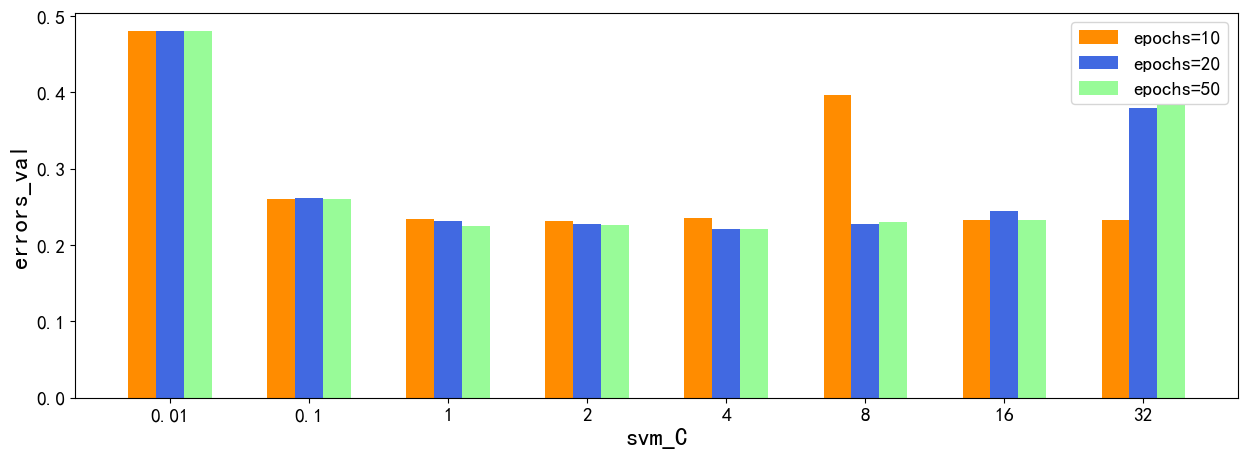

In [119]:
plt.figure(figsize=(15,5), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.bar(np.array(range(0,len(exec_result.query('epochs ==10'))))+0.8, exec_result.query('epochs ==10')['errors_val'].values.tolist(), width=0.2, color='darkorange', label='epochs=10')
plt.bar(np.array(range(0,len(exec_result.query('epochs ==20'))))+1, exec_result.query('epochs ==20')['errors_val'].values.tolist(), width=0.2, color='royalblue', label='epochs=20')
plt.bar(np.array(range(0,len(exec_result.query('epochs ==50'))))+1.2, exec_result.query('epochs ==50')['errors_val'].values.tolist(), width=0.2, color='palegreen', label='epochs=50')
# plt.plot([0,8],[10,10],c='g',ls='--')
plt.xlabel('svm_C', fontsize=18, fontweight='bold')
plt.ylabel('errors_val', fontsize=18, fontweight='bold')
plt.xticks(range(1,len(exec_result.query('epochs ==10'))+1), [0.01, 0.1, 1, 2, 4, 8, 16, 32], fontsize=14)
plt.yticks(fontsize=14)
plt.legend(fontsize=14)
plt.show()

### 测试模型

In [126]:
svm,loss_train,loss_val,trainError,valError = learnPredictor(X_train, Y_train, X_val, Y_val,  
                                                        epochs=20, 
                                                        C=4)  

[epoch=20 c=4] Loss(train|val)=0.387742|0.441011 Error rate(train|val))=0.193871|0.220506


/home/shaw/anaconda3/envs/nlp/lib/python3.10/site-packages/sklearn/svm/_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


In [127]:
pred_test = svm.predict(X_test)
loss_test = hinge_loss(Y_test, pred_test)
# 计算测试集的错误率
testError = len([p for p,y in zip(pred_test,Y_test) if p != y])/len(pred_test)

print ("train error = %4f, validate error = %4f, test error = %4f" % (trainError, valError, testError))

train error = 0.193871, validate error = 0.220506, test error = 0.229206
